Saved: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/inputs/waveform_aligned.npz
N = 72000
dt = 0.1
t range = 0.0 7199.900000000001
tau_to_peak range = -3600.0 3599.9000000000005
raw peak index = 36000
raw peak time = -3.2741809263825417e-09
aligned peak index = 36000
aligned peak tau = 0.0


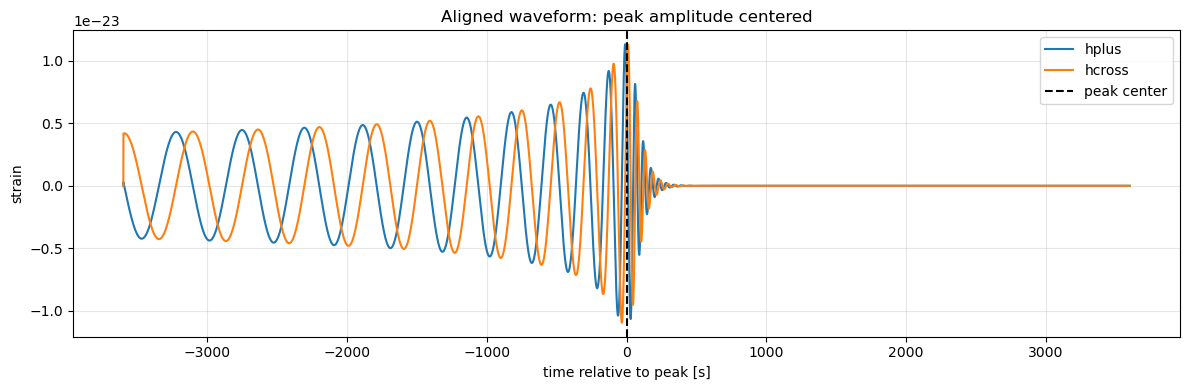

In [ ]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()

INPUT_DIR = BASE_DIR / "inputs"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

RAW_WAVEFORM = INPUT_DIR / "my_waveform.npz"
ALIGNED_WAVEFORM = INPUT_DIR / "waveform_aligned.npz"

DATA_DURATION = 7200.0   # total data stretch [s]
DT = 0.1                 # sampling time [s]

data = np.load(RAW_WAVEFORM)

t_raw = np.asarray(data["t"], dtype=float)
hp_raw = np.asarray(data["hplus"], dtype=float)
hc_raw = np.asarray(data["hcross"], dtype=float)

if not (len(t_raw) == len(hp_raw) == len(hc_raw)):
    raise ValueError("t, hplus, and hcross must have the same length.")

# Peak-amplitude alignment
amp_raw = np.sqrt(hp_raw**2 + hc_raw**2)
peak_index_raw = int(np.argmax(amp_raw))
peak_time_raw = t_raw[peak_index_raw]

# Shift raw waveform so peak amplitude is at tau = 0
t_peak_centered = t_raw - peak_time_raw

# Desired detector/data grid
n = int(DATA_DURATION / DT)
t = np.arange(n) * DT

# Centered time axis: peak is placed at tau = 0
tau = t - DATA_DURATION / 2.0

# Interpolate waveform onto centered grid
hp = np.interp(tau, t_peak_centered, hp_raw, left=0.0, right=0.0)
hc = np.interp(tau, t_peak_centered, hc_raw, left=0.0, right=0.0)

np.savez(
    ALIGNED_WAVEFORM,
    t=t,                 # starts at zero
    tau_to_peak=tau,     # centered, peak at zero
    hplus=hp,
    hcross=hc,
)

print("Saved:", ALIGNED_WAVEFORM)
print("N =", n)
print("dt =", DT)
print("t range =", t.min(), t.max())
print("tau_to_peak range =", tau.min(), tau.max())
print("raw peak index =", peak_index_raw)
print("raw peak time =", peak_time_raw)
print("aligned peak index =", int(np.argmax(np.sqrt(hp**2 + hc**2))))
print("aligned peak tau =", tau[int(np.argmax(np.sqrt(hp**2 + hc**2)))])

plt.figure(figsize=(12, 4))
plt.plot(t, hp, label="hplus")
plt.plot(t, hc, label="hcross")
plt.axvline(0.0, color="k", ls="--", label="peak center")
plt.xlabel("time relative to peak [s]")
plt.ylabel("strain")
plt.title("Aligned waveform: peak amplitude centered")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_aligned_waveform_peak_centered.png", dpi=150)
plt.show()

You are using an orbit file in a version that might not be fully supported


Loaded peak-centered waveform:
  N         = 72000
  dt        = 0.0999999999999659 s
  t range   = [0.0, 7199.900000000001]
  tau range = [-3600.0, 3599.9000000000005]
  peak idx  = 36000
  peak tau  = 0.0
  hp range  = [-1.064e-23, 1.130e-23]
  hc range  = [-1.094e-23, 1.126e-23]

Orbit mapping:
  orbit range     = [61171239.327664, 63761239.327664]
  peak_time_lisa  = 62899239.327664
  t_lisa range    = [62895639.327664, 62902839.227664]
  t_lisa at peak  = 62899239.327664

Computing LISA GW response...


You are using an orbit file in a version that might not be fully supported



Saved GW-only links: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/six_links_gw_only.csv
Saved GW response HDF5 for lisainstrument: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/gws.h5


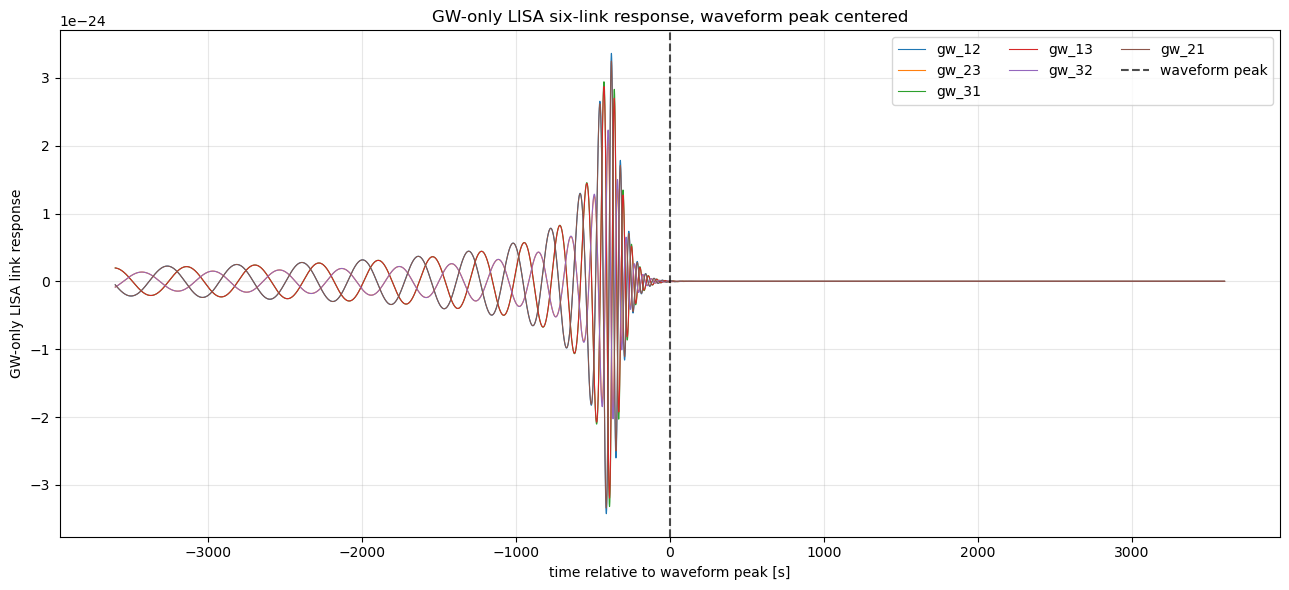

Saved plot: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/02_gw_only_six_links_peak_centered.png


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py

from lisagwresponse import ReadStrain


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path.cwd()

INPUT_DIR = BASE_DIR / "inputs"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

WAVEFORM_FILE = INPUT_DIR / "waveform_aligned.npz"
ORBITS_FILE = INPUT_DIR / "orbits.h5"

GW_FILE = OUTPUT_DIR / "gws.h5"
GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"
PLOT_FILE = OUTPUT_DIR / "02_gw_only_six_links_peak_centered.png"


# ============================================================
# Settings
# ============================================================

RA = np.pi / 4
DEC = 0.3

LINKS = [12, 23, 31, 13, 32, 21]
LINK_LABELS = ["12", "23", "31", "13", "32", "21"]

PEAK_OFFSET_DAYS_FROM_ORBIT_START = 20.0


# ============================================================
# Helpers
# ============================================================

def read_orbit_time_range(orbits_file):
    with h5py.File(orbits_file, "r") as f:
        attrs = dict(f.attrs)
        t0 = float(attrs["t0"])
        dt = float(attrs["dt"])
        size = int(attrs["size"])
        t1 = t0 + dt * (size - 1)
    return t0, t1, dt, size


# ============================================================
# Main
# ============================================================

data = np.load(WAVEFORM_FILE)

t_data = np.asarray(data["t"], dtype=float)
tau = np.asarray(data["tau_to_peak"], dtype=float)
hplus = np.asarray(data["hplus"], dtype=float)
hcross = np.asarray(data["hcross"], dtype=float)

dt = float(np.median(np.diff(t_data)))
n = len(t_data)

print("Loaded peak-centered waveform:")
print(f"  N         = {n}")
print(f"  dt        = {dt} s")
print(f"  t range   = [{t_data.min()}, {t_data.max()}]")
print(f"  tau range = [{tau.min()}, {tau.max()}]")
print(f"  peak idx  = {np.argmax(np.sqrt(hplus**2 + hcross**2))}")
print(f"  peak tau  = {tau[np.argmax(np.sqrt(hplus**2 + hcross**2))]}")
print(f"  hp range  = [{hplus.min():.3e}, {hplus.max():.3e}]")
print(f"  hc range  = [{hcross.min():.3e}, {hcross.max():.3e}]")

orbit_t0, orbit_t1, orbit_dt, orbit_size = read_orbit_time_range(ORBITS_FILE)

peak_time_lisa = orbit_t0 + PEAK_OFFSET_DAYS_FROM_ORBIT_START * 86400.0
t_lisa = peak_time_lisa + tau

print("\nOrbit mapping:")
print(f"  orbit range     = [{orbit_t0}, {orbit_t1}]")
print(f"  peak_time_lisa  = {peak_time_lisa}")
print(f"  t_lisa range    = [{t_lisa.min()}, {t_lisa.max()}]")
print(f"  t_lisa at peak  = {t_lisa[np.argmax(np.sqrt(hplus**2 + hcross**2))]}")

if t_lisa.min() < orbit_t0 or t_lisa.max() > orbit_t1:
    raise ValueError("Mapped waveform lies outside orbit file time range.")

print("\nComputing LISA GW response...")

source = ReadStrain(
    t_lisa,
    hplus,
    hcross,
    orbits=str(ORBITS_FILE),
    ra=RA,
    dec=DEC,
)

y_gw = source.compute_gw_response(t_lisa, LINKS)

df = pd.DataFrame(
    np.column_stack([t_data, tau, t_lisa, y_gw]),
    columns=[
        "t",
        "tau_to_peak",
        "t_lisa",
        "gw_12",
        "gw_23",
        "gw_31",
        "gw_13",
        "gw_32",
        "gw_21",
    ],
)

#plot LISA GW-only response of what is saved in the data frame 
plt.figure(figsize=(13, 6))
for lab in LINK_LABELS:
    plt.plot(t_lisa, df[f"gw_{lab}"], lw=0.8, label=f"gw_{lab}")
plt.axvline(0.0, color="k", ls="--", alpha=
0.7, label="waveform peak")
plt.xlabel("time relative to waveform peak [s]")
plt.ylabel("GW-only LISA link response")
plt.title("GW-only LISA six-link response, waveform peak centered")
plt.grid(alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=150)
plt.show()


#df.to_csv(GW_ONLY_CSV, index=False)
#print(f"\nSaved GW-only links: {GW_ONLY_CSV}")

#if GW_FILE.exists():
#    GW_FILE.unlink()

#source.write(
#    str(GW_FILE),
#    t0=float(t_lisa[0]),
#    dt=dt,
#    size=n,
#)

#print(f"Saved GW response HDF5 for lisainstrument: {GW_FILE}")

#plt.figure(figsize=(13, 6))

#for lab in LINK_LABELS:
#    plt.plot(t_lisa, df[f"gw_{lab}"], lw=0.8, label=f"gw_{lab}")

#plt.axvline(0.0, color="k", ls="--", alpha=0.7, label="waveform peak")
#plt.xlabel("time relative to waveform peak [s]")
#plt.ylabel("GW-only LISA link response")
#plt.title("GW-only LISA six-link response, waveform peak centered")
#plt.grid(alpha=0.3)
#plt.legend(ncol=3)
#plt.tight_layout()
#plt.savefig(PLOT_FILE, dpi=150)
#plt.show()

#print(f"Saved plot: {PLOT_FILE}")

Using default set of locking beatnote frequencies might cause interferometric beatnote frequencies to fall outside the requirement range of 5..25 MHz


Loaded GW timing:
  N        = 72000
  dt       = 0.09999999999990905 s
  t range  = [0.0, 7199.900000000001]
  tau range= [-3600.0, 3599.9000000000005]
  t0_lisa  = 62895639.327664

Running LISA Instrument...
Saved instrument output: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/lisa_instrument_output.h5
Saved noisy six-link CSV: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/six_links_noisy.csv
   sample    t  tau_to_peak        t_lisa    noisy_12   noisy_23  \
0       0  0.0      -3600.0  6.289564e+07   61.698287   3.665479   
1       1  0.1      -3599.9  6.289564e+07  -15.109021  15.912815   
2       2  0.2      -3599.8  6.289564e+07  -27.169418  44.170376   
3       3  0.3      -3599.7  6.289564e+07   36.125757  66.893846   
4       4  0.4      -3599.6  6.289564e+07  109.798830  58.101826   

       noisy_31    noisy_13   noisy_32      noisy_21  
0  4.163457e-15   55.586050   8.746846 -9.280928e-16  
1  4.426325e-15  -16.432360  26.025214 -2.635264e-

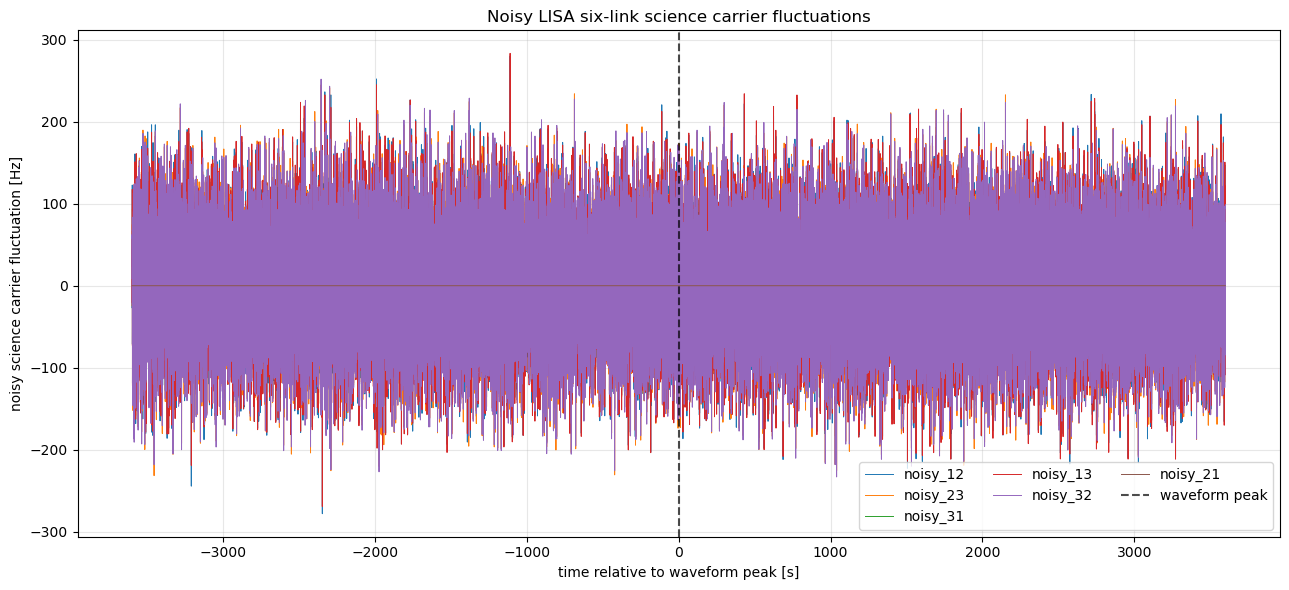

Saved plot: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/03_noisy_six_links.png


In [19]:
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt

from lisainstrument import Instrument


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"
GW_FILE = OUTPUT_DIR / "gws.h5"

INPUT_DIR = BASE_DIR / "inputs"
ORBITS_FILE = INPUT_DIR / "orbits.h5"

INSTRUMENT_FILE = OUTPUT_DIR / "lisa_instrument_output.h5"
NOISY_CSV = OUTPUT_DIR / "six_links_noisy.csv"
PLOT_FILE = OUTPUT_DIR / "03_noisy_six_links.png"


# ============================================================
# Settings
# ============================================================

LINK_LABELS = ["12", "23", "31", "13", "32", "21"]
SEED = 12345


# ============================================================
# Load timing metadata from GW-only response
# ============================================================

gw = pd.read_csv(GW_ONLY_CSV)

t_data = gw["t"].to_numpy()
tau = gw["tau_to_peak"].to_numpy()
t_lisa = gw["t_lisa"].to_numpy()

dt = float(np.median(np.diff(t_data)))
n = len(t_data)
t0_lisa = float(t_lisa[0])

print("Loaded GW timing:")
print(f"  N        = {n}")
print(f"  dt       = {dt} s")
print(f"  t range  = [{t_data.min()}, {t_data.max()}]")
print(f"  tau range= [{tau.min()}, {tau.max()}]")
print(f"  t0_lisa  = {t0_lisa}")


# ============================================================
# Run LISA Instrument
# ============================================================

print("\nRunning LISA Instrument...")

if INSTRUMENT_FILE.exists():
    INSTRUMENT_FILE.unlink()

instrument = Instrument(
    size=n,
    dt=dt,
    t0=t0_lisa,
    orbits=str(ORBITS_FILE),
    gws=str(GW_FILE),
    seed=SEED,
)

if hasattr(instrument, "export_hdf5"):
    instrument.export_hdf5(
        path=str(INSTRUMENT_FILE),
        overwrite=True,
    )
elif hasattr(instrument, "write"):
    instrument.write(
        str(INSTRUMENT_FILE),
        overwrite=True,
    )
else:
    instrument.simulate()
    raise RuntimeError("Could not find export_hdf5() or write().")

print(f"Saved instrument output: {INSTRUMENT_FILE}")


# ============================================================
# Extract noisy science carrier fluctuations
# ============================================================

GROUP = "debug/sci_carrier_fluctuations"

with h5py.File(INSTRUMENT_FILE, "r") as f:
    arrays = []

    for lab in LINK_LABELS:
        path = f"{GROUP}/{lab}"

        if path not in f:
            raise KeyError(
                f"Missing dataset {path}. "
                "Print HDF5 tree and check dataset names."
            )

        arrays.append(np.asarray(f[path]))

m = min(len(a) for a in arrays)
m = min(m, n)

df = pd.DataFrame({
    "sample": np.arange(m),
    "t": t_data[:m],
    "tau_to_peak": tau[:m],
    "t_lisa": t_lisa[:m],
})

for lab, arr in zip(LINK_LABELS, arrays):
    df[f"noisy_{lab}"] = arr[:m]

df.to_csv(NOISY_CSV, index=False)

print(f"Saved noisy six-link CSV: {NOISY_CSV}")
print(df.head())


# ============================================================
# Plot noisy links
# ============================================================

plt.figure(figsize=(13, 6))

for lab in LINK_LABELS:
    plt.plot(df["tau_to_peak"], df[f"noisy_{lab}"], lw=0.7, label=f"noisy_{lab}")

plt.axvline(0.0, color="k", ls="--", alpha=0.7, label="waveform peak")
plt.xlabel("time relative to waveform peak [s]")
plt.ylabel("noisy science carrier fluctuation [Hz]")
plt.title("Noisy LISA six-link science carrier fluctuations")
plt.grid(alpha=0.3)
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=150)
plt.show()

print(f"Saved plot: {PLOT_FILE}")

You are using a measurement file in a version that might not be fully supported (got '2.1.0', official support up to '2.0')


Loading instrument output with PyTDI...
Loaded PyTDI Data:
  fs      = 10.000000000009095 Hz
  skipped = 0
  dt_meta = 0.09999999999990905 s
Using delay derivatives.

Building Michelson X2, Y2, Z2...
Evaluating TDI...

Centered TDI timing:
  n             = 72000
  tau min       = -3600.000 s
  tau max       = 3599.900 s
  tau center    = 0.000000 s
  center index  = 36000

TDI diagnostics:
  X2: min=-8.168e+01, max=3.644e+01, std=7.360e-01
  Y2: min=-1.464e+02, max=1.519e+02, std=4.890e+00
  Z2: min=-1.765e+02, max=1.528e+02, std=4.969e+00
  A2: min=-1.249e+02, max=1.124e+02, std=3.609e+00
  E2: min=-1.831e+02, max=1.739e+02, std=5.921e+00
  T2: min=-7.693e+01, max=4.986e+01, std=1.031e+00

Saved TDI CSV: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/tdi_michelson_XYZ_AET.csv


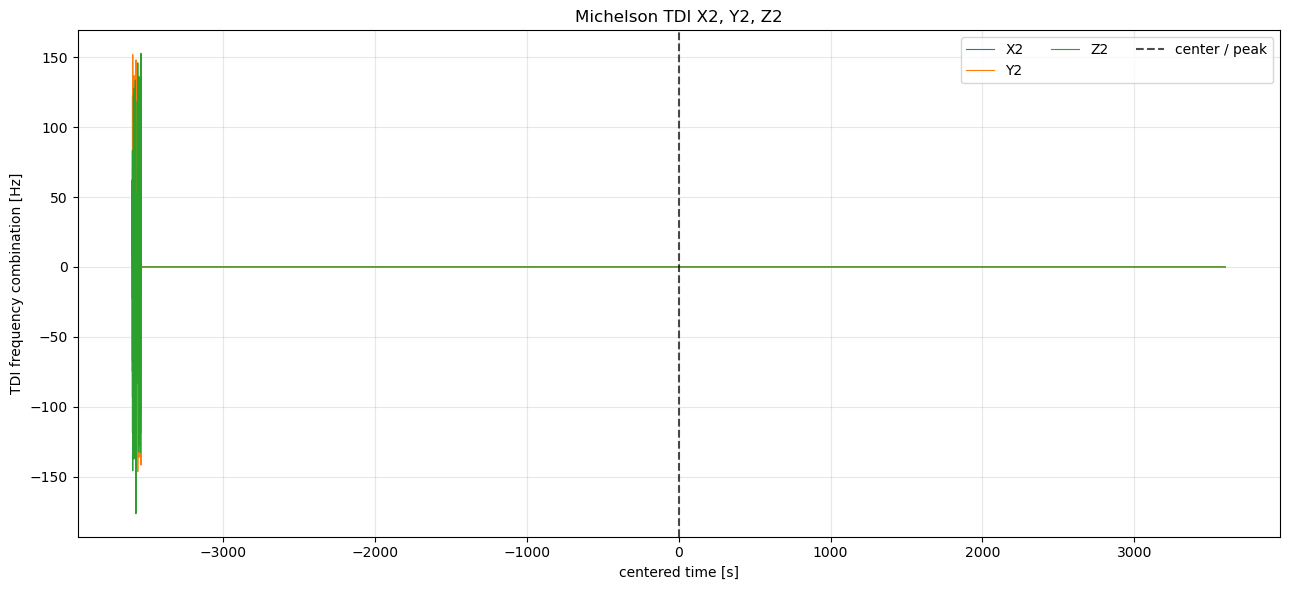

Saved plot: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/04_tdi_XYZ_centered.png


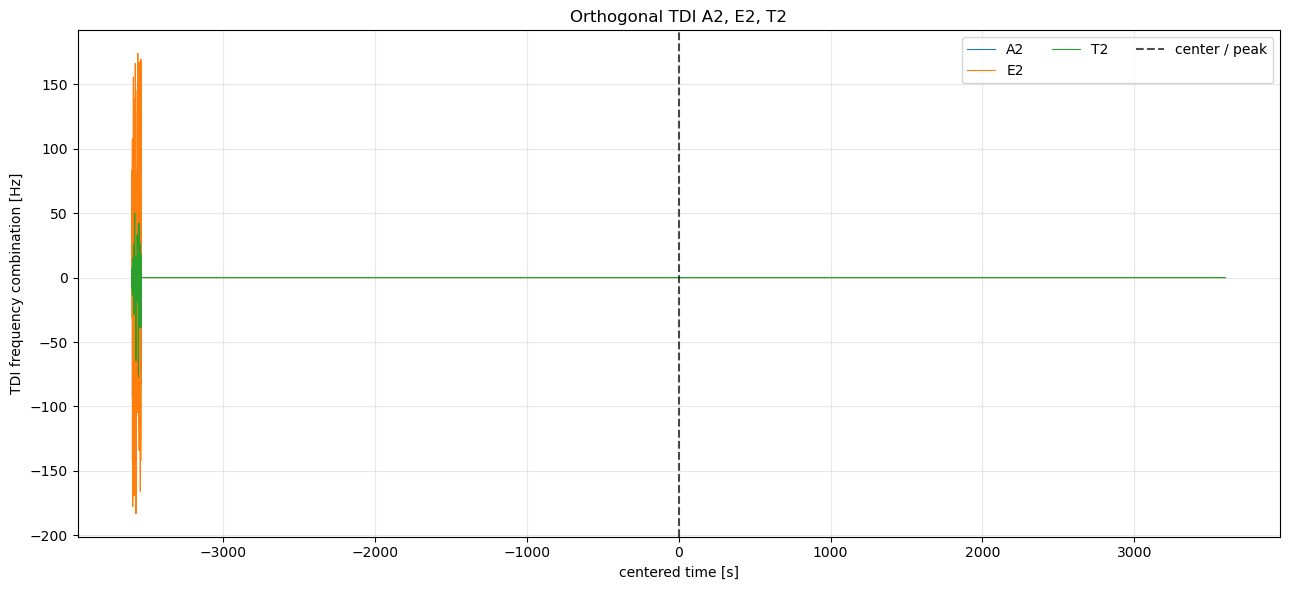

Saved plot: /Users/shubhanshutiwari/Desktop/LISA-TF/lisa_link_sim/outputs/plots/04_tdi_AET_centered.png


In [22]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pytdi import Data
import pytdi.michelson


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path.cwd()

OUTPUT_DIR = BASE_DIR / "outputs"
PLOT_DIR = OUTPUT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

INSTRUMENT_FILE = OUTPUT_DIR / "lisa_instrument_output.h5"
GW_ONLY_CSV = OUTPUT_DIR / "six_links_gw_only.csv"

TDI_CSV = OUTPUT_DIR / "tdi_michelson_XYZ_AET.csv"
PLOT_XYZ = PLOT_DIR / "04_tdi_XYZ_centered.png"
PLOT_AET = PLOT_DIR / "04_tdi_AET_centered.png"


# ============================================================
# Settings
# ============================================================

SKIPPED = 0
EDGE_CROP = 0
UNIT = "frequency"
INTERP_ORDER = 31
GENERATION = 2


# ============================================================
# Helpers
# ============================================================

def get_delay_derivatives_if_available(data):
    if hasattr(data, "delay_derivatives"):
        return data.delay_derivatives
    if hasattr(data, "delay_derivs"):
        return data.delay_derivs
    if hasattr(data, "derivatives"):
        return data.derivatives
    return None


def crop(arr, edge):
    if edge <= 0:
        return arr

    if len(arr) <= 2 * edge:
        print(f"Array too short for EDGE_CROP={edge}; not cropping.")
        return arr

    return arr[edge:-edge]


def plot_channels(x, channels, title, ylabel, outfile):
    plt.figure(figsize=(13, 6))

    for name, y in channels.items():
        plt.plot(x, y, lw=0.8, label=name)

    plt.axvline(0.0, color="k", ls="--", alpha=0.7, label="center / peak")
    plt.xlabel("centered time [s]")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend(ncol=3)
    plt.tight_layout()
    plt.savefig(outfile, dpi=150)
    plt.show()

    print(f"Saved plot: {outfile}")


# ============================================================
# Main
# ============================================================

def main():
    gw_meta = pd.read_csv(GW_ONLY_CSV)

    if "t" not in gw_meta.columns:
        raise ValueError("Expected column t in six_links_gw_only.csv")

    dt_tdi = float(np.median(np.diff(gw_meta["t"].to_numpy())))

    print("Loading instrument output with PyTDI...")

    data = Data.from_instrument(
        str(INSTRUMENT_FILE),
        signals="fluctuations",
        skipped=SKIPPED,
    )

    print("Loaded PyTDI Data:")
    print(f"  fs      = {data.fs} Hz")
    print(f"  skipped = {SKIPPED}")
    print(f"  dt_meta = {dt_tdi} s")

    delay_derivatives = get_delay_derivatives_if_available(data)

    if delay_derivatives is None:
        print("Warning: no delay derivatives found.")
    else:
        print("Using delay derivatives.")

    if GENERATION == 2:
        X_comb = pytdi.michelson.X2
        Y_comb = pytdi.michelson.Y2
        Z_comb = pytdi.michelson.Z2
        suffix = "2"
    else:
        X_comb = pytdi.michelson.X1
        Y_comb = pytdi.michelson.Y1
        Z_comb = pytdi.michelson.Z1
        suffix = "1"

    build_kwargs = {"order": INTERP_ORDER}

    if delay_derivatives is not None:
        build_kwargs["delay_derivatives"] = delay_derivatives

    print(f"\nBuilding Michelson X{suffix}, Y{suffix}, Z{suffix}...")

    X_built = X_comb.build(data.delays, data.fs, **build_kwargs)
    Y_built = Y_comb.build(data.delays, data.fs, **build_kwargs)
    Z_built = Z_comb.build(data.delays, data.fs, **build_kwargs)

    print("Evaluating TDI...")

    X = X_built(data.measurements, unit=UNIT)
    Y = Y_built(data.measurements, unit=UNIT)
    Z = Z_built(data.measurements, unit=UNIT)

    A = (Z - X) / np.sqrt(2.0)
    E = (X - 2.0 * Y + Z) / np.sqrt(6.0)
    T = (X + Y + Z) / np.sqrt(3.0)

    n = min(len(X), len(Y), len(Z), len(A), len(E), len(T))

    X = X[:n]
    Y = Y[:n]
    Z = Z[:n]
    A = A[:n]
    E = E[:n]
    T = T[:n]

    # Optional edge crop
    X = crop(X, EDGE_CROP)
    Y = crop(Y, EDGE_CROP)
    Z = crop(Z, EDGE_CROP)
    A = crop(A, EDGE_CROP)
    E = crop(E, EDGE_CROP)
    T = crop(T, EDGE_CROP)

    n = min(len(X), len(Y), len(Z), len(A), len(E), len(T))

    X = X[:n]
    Y = Y[:n]
    Z = Z[:n]
    A = A[:n]
    E = E[:n]
    T = T[:n]

    # ========================================================
    # Critical fix:
    # Build centered time axis from final TDI length.
    # This avoids PyTDI internal trimming / skipped-sample confusion.
    # ========================================================

    tau = (np.arange(n) - n // 2) * dt_tdi
    t = tau - tau.min()
    sample = np.arange(n)

    print("\nCentered TDI timing:")
    print(f"  n             = {n}")
    print(f"  tau min       = {tau.min():.3f} s")
    print(f"  tau max       = {tau.max():.3f} s")
    print(f"  tau center    = {tau[n // 2]:.6f} s")
    print(f"  center index  = {n // 2}")

    print("\nTDI diagnostics:")
    for name, arr in {
        f"X{suffix}": X,
        f"Y{suffix}": Y,
        f"Z{suffix}": Z,
        f"A{suffix}": A,
        f"E{suffix}": E,
        f"T{suffix}": T,
    }.items():
        print(
            f"  {name}: "
            f"min={np.min(arr):.3e}, "
            f"max={np.max(arr):.3e}, "
            f"std={np.std(arr):.3e}"
        )

    df = pd.DataFrame({
        "sample": sample,
        "t": t,
        "tau_centered": tau,
        f"X{suffix}": X,
        f"Y{suffix}": Y,
        f"Z{suffix}": Z,
        f"A{suffix}": A,
        f"E{suffix}": E,
        f"T{suffix}": T,
    })

    df.to_csv(TDI_CSV, index=False)
    print(f"\nSaved TDI CSV: {TDI_CSV}")

    plot_channels(
        tau,
        {f"X{suffix}": X, f"Y{suffix}": Y, f"Z{suffix}": Z},
        f"Michelson TDI X{suffix}, Y{suffix}, Z{suffix}",
        "TDI frequency combination [Hz]",
        PLOT_XYZ,
    )

    plot_channels(
        tau,
        {f"A{suffix}": A, f"E{suffix}": E, f"T{suffix}": T},
        f"Orthogonal TDI A{suffix}, E{suffix}, T{suffix}",
        "TDI frequency combination [Hz]",
        PLOT_AET,
    )


if __name__ == "__main__":
    main()